# Paso 8 · Especificaciones → bounds (con Python)

Notebook del **Paso 8**: tres especificaciones sobre el lazo cerrado y cómo se traducen en *zonas prohibidas* para el nominal $L_0$.

| Concepto matemático | Concepto de programación |
|---|---|
| $|T|\le W_s$, banda de seguimiento, $|S|\le W_d$ | funciones-especificación que devuelven `True/False` |
| bound = condición sobre $L_0$ para **toda** la familia | rejilla (fase × dB) y máscaras booleanas |
| intersección de especificaciones | operador `&` entre arrays |
| bound a una fase dada | recorrer una columna de la máscara |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from nbhelp import db, wrapfase, carta_nichols, poligono, AZUL, NARANJA, TINTA, GRIS, VERDE, MORADO
from qft import P, P0, ratio, spec_ok, template, TU, TL, delta_db, WD, WS, Tdb

## 1. Qué se exige al lazo cerrado: tres especificaciones

Para **toda** planta de la familia, en cada $\omega$:

1. **Estabilidad robusta**: $|T(j\omega)|\le W_s=1.2$ (1.58 dB). Pico acotado ⇒ margen.
2. **Seguimiento**: las $|T_i|$ de toda la familia caben en la banda $[T_L,T_U]$, así que su **dispersión** no puede pasar de $\delta(\omega)=|T_U|_{\rm dB}-|T_L|_{\rm dB}$.
3. **Rechazo de perturbación a la salida**: $|S|\le W_d(\omega)$ ($0.3$ hasta $0.5$ rad/s, $0.5$ hasta $1$, y $10$ después).

In [3]:
print(f"W_s = {WS} = {db(WS):.2f} dB")
print(f"{'ω':>5} {'TU dB':>8} {'TL dB':>8} {'δ(ω) dB':>9} {'Wd':>6}")
for wv in (0.3, 0.5, 1, 2, 3, 5, 10):
    print(f"{wv:>5g} {db(TU(wv)):>8.2f} {db(TL(wv)):>8.2f} {float(delta_db(wv)):>9.1f} {float(WD(wv)):>6.1f}")

W_s = 1.2 = 1.58 dB
    ω    TU dB    TL dB   δ(ω) dB     Wd
  0.3     0.00    -0.79       0.8    0.3
  0.5     0.01    -2.09       2.1    0.3
    1     0.04    -6.87       6.9    0.5
    2     0.14   -17.32      17.5   10.0
    3     0.26   -25.81      26.1   10.0
    5     0.30   -37.92      38.2   10.0
   10    -4.09   -55.44      51.3   10.0


## 2. Deslizar el template: cómo aparece el bound ($\omega=2$)

Con $L_0=|L_0|e^{j\varphi}$ **fijo**, la familia es $L_i=L_0\cdot r_i$ con $r_i=P_i/P_0$ (el *template relativo*). Para cada posición de $L_0$ preguntamos: ¿cumplen *todas* las $L_i$? Por ejemplo, a $-150^\circ$ barremos la ganancia:

In [4]:
w0 = 2.0
r = ratio(w0)                                    # P_i / P_0 para las 221 plantas
def cumple(fase_deg, g_db, w=w0):
    L0 = np.array(10**(g_db/20) * np.exp(1j*np.radians(fase_deg)))
    return [bool(x) for x in spec_ok(w, L0, ratio(w))]      # [estabilidad, seguimiento, perturbación]

print(f"{'|L0| dB':>8} {'estab':>6} {'segui':>6} {'pert':>6}   todas")
for g in range(-10, 30, 4):
    e, s, d = cumple(-150, g)
    print(f"{g:>8} {str(e):>6} {str(s):>6} {str(d):>6}   {e and s and d}")

 |L0| dB  estab  segui   pert   todas
     -10  False  False   True   False
      -6  False   True   True   False
      -2  False   True   True   False
       2  False   True   True   False
       6  False   True   True   False
      10  False   True   True   False
      14  False   True   True   False
      18   True   True   True   True
      22   True   True   True   True
      26   True   True   True   True


A $-150^\circ$ hay una **zona prohibida** de ganancia: mientras $|L_0|$ sea pequeño, alguna planta del template cae dentro del óvalo de $|T|=1.58$ dB (la tabla lo muestra: falla la estabilidad). Lo localizamos con una búsqueda fina:

In [5]:
def bound(fase_deg, w, gs=np.arange(-60, 60.01, 0.25)):
    """Mínimo |L0| (dB) tal que, a esa fase, se cumplen las 3 especificaciones por encima. Devuelve el intervalo prohibido."""
    ok = np.array([all(cumple(fase_deg, g, w)) for g in gs])
    prohib = gs[~ok]
    return (prohib.min(), prohib.max()) if len(prohib) else None

b = bound(-150, 2.0)
print(f"a ω=2, -150°: |L0| tiene que quedar por encima de {b[1]} dB  (diapositiva del ejercicio: bound = 14 dB)")

a ω=2, -150°: |L0| tiene que quedar por encima de 14.0 dB  (diapositiva del ejercicio: bound = 14 dB)


## 3. Un mapa de posiciones permitidas

Repetimos para todas las fases: una **máscara** booleana (fase × dB). La intersección de las tres especificaciones es el `&` de las tres.

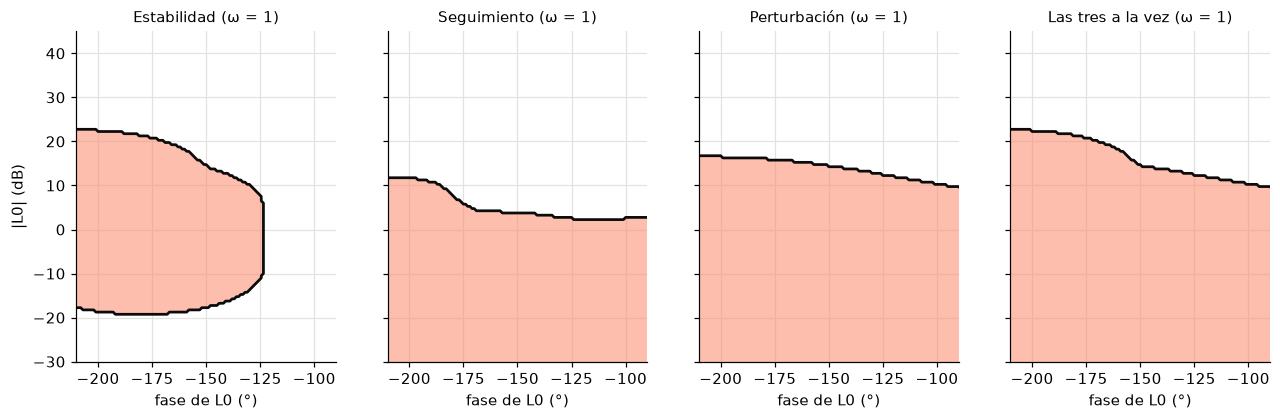

celdas prohibidas por cada especificación: [8986, 20110, 23207] y por la intersección: 24185


In [6]:
PH = np.arange(-250, -69, 1.0); GG = np.arange(-50, 50.5, 0.5)
def mapas(w):
    X, Y = np.meshgrid(PH, GG)
    L0 = 10**(Y/20) * np.exp(1j*np.radians(X))
    return spec_ok(w, L0, ratio(w))          # (estab, segui, pert), cada una de forma (len(GG), len(PH))

fig, axs = plt.subplots(1, 4, figsize=(14, 3.9), sharey=True)
a, s, d = mapas(1.0)
for ax, m, t in zip(axs, (a, s, d, a & s & d), ("Estabilidad", "Seguimiento", "Perturbación", "Las tres a la vez")):
    ax.pcolormesh(PH, GG, np.where(m, np.nan, 1.0), cmap="Reds", vmin=0, vmax=2.5, alpha=0.55, shading="auto")
    ax.contour(PH, GG, m.astype(float), levels=[0.5], colors=[TINTA], linewidths=1.8)
    ax.set_xlim(-210, -90); ax.set_ylim(-30, 45); ax.set_title(t + " (ω = 1)", fontsize=10); ax.set_xlabel("fase de L0 (°)")
axs[0].set_ylabel("|L0| (dB)"); plt.show()
print("celdas prohibidas por cada especificación:", [int((~m).sum()) for m in (a, s, d)], "y por la intersección:", int((~(a & s & d)).sum()))

Rojo = *el nominal no puede estar aquí*. Compara los números de celdas prohibidas: en $\omega=1$ la especificación más exigente es la de perturbación, luego el seguimiento y por último la estabilidad.

## 4. Los bounds de todas las frecuencias

El contorno de la zona permitida en cada $\omega$ es el **bound**. A baja frecuencia exige mucha ganancia; a alta frecuencia casi desaparece (cualquier $L_0$ pequeño vale).

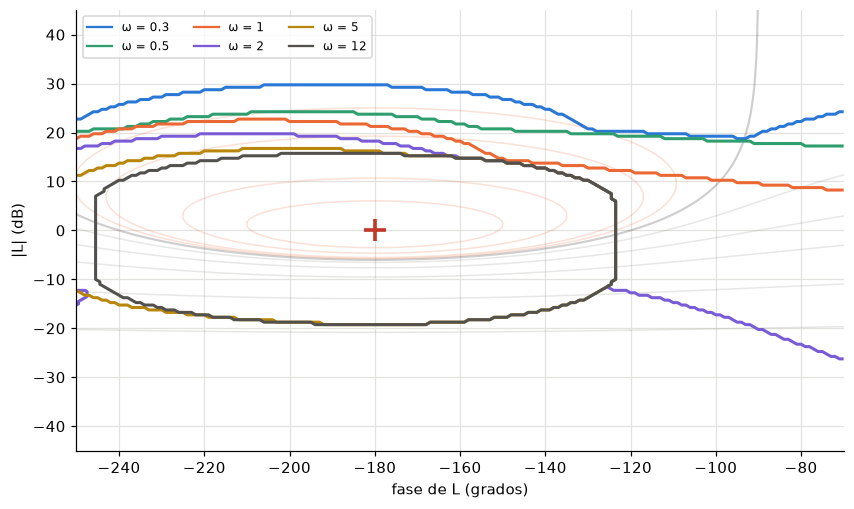

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2)); carta_nichols(ax, (-250, -70), (-45, 45), alpha=0.2)
for wv, c in zip((0.3, 0.5, 1, 2, 5, 12), (AZUL, VERDE, NARANJA, MORADO, "#b8860b", GRIS)):
    a, s, d = mapas(wv); ax.contour(PH, GG, (a & s & d).astype(float), levels=[0.5], colors=[c], linewidths=2)
    ax.plot([], [], color=c, label=f"ω = {wv:g}")
ax.legend(ncol=3, fontsize=8); plt.show()

## 5. Cómo se usa un bound

Diseñar = mover $L_0(j\omega)$ (con $G$) para que, **en cada $\omega$ de la lista**, caiga en la zona permitida. Y después se verifica con la familia entera (Paso 9).

## 6. Ejercicio del Paso 8

A $\omega=2$ el nominal está en $L_0=3.16\angle-150^\circ$ (10 dB). Los otros puntos del template, respecto del nominal: $(1,3)$: $+29.7^\circ$, $-4.15$ dB; $(5,1)$: $0^\circ$, $+13.98$ dB; $(5,3)$: $+29.7^\circ$, $+9.83$ dB.

1. $|T|$ en dB de cada planta. 2. ¿Se cumple $|T|\le1.58$ dB? ¿Cuál es la peor? 3. ¿Se cumple la variación de seguimiento $\delta(2)=17.5$ dB? 4. ¿Cuántos dB hay que subir el nominal para cumplir (bound a $-150^\circ$: 14 dB)?

**Tu turno.**

In [8]:
L0 = 10**(10/20) * np.exp(1j*np.radians(-150))
# k1) L_k = L0 * (cociente de cada planta) y |T|_dB = db(L/(1+L))
# 2) máximo de |T| vs 1.58 dB
# 3) dispersión max(|T|)-min(|T|) vs delta(2)
# 4) subida necesaria
# escribe aquí tu código

In [9]:
L0 = 10**(10/20) * np.exp(1j*np.radians(-150))
dif = {"(1,1)": (0, 0), "(1,3)": (29.7, -4.15), "(5,1)": (0, 13.98), "(5,3)": (29.7, 9.83)}
tdb = {}
for k, (dp, dg) in dif.items():
    L = L0 * 10**(dg/20) * np.exp(1j*np.radians(dp)); tdb[k] = db(L/(1+L)); print(f"planta {k}: |T| = {tdb[k]:6.2f} dB")
peor = max(tdb, key=tdb.get)
print(f"2) la peor es {peor} con {tdb[peor]:.2f} dB  ->  {'cumple' if tdb[peor] <= 1.58 else 'NO cumple'} |T| <= 1.58 dB")
disp = max(tdb.values()) - min(tdb.values())
print(f"3) dispersión = {disp:.2f} dB frente a δ(2) = {float(delta_db(2.0)):.1f} dB -> {'cumple' if disp <= delta_db(2.0) else 'NO cumple'}")
print(f"4) hay que subir como mínimo 14 - 10 = {14-10} dB (el bound a -150° está en 14 dB)")

planta (1,1): |T| =   2.58 dB
planta (1,3): |T| =   1.28 dB
planta (5,1): |T| =   0.48 dB
planta (5,3): |T| =   0.42 dB
2) la peor es (1,1) con 2.58 dB  ->  NO cumple |T| <= 1.58 dB
3) dispersión = 2.16 dB frente a δ(2) = 17.5 dB -> cumple
4) hay que subir como mínimo 14 - 10 = 4 dB (el bound a -150° está en 14 dB)


## 7. Resumen

- Tres especificaciones (estabilidad $|T|\le W_s$, seguimiento por dispersión, rechazo $|S|\le W_d$) se evalúan sobre **toda** la familia.
- Para cada $\omega$ y cada posición de $L_0$ se obtiene un booleano; el conjunto permitido es un **mapa** y su frontera el **bound**.
- Cumplir los bounds con el nominal ⇒ cumplir las especificaciones para toda la familia (en las frecuencias de la lista).

**Siguiente:** Paso 9, loop shaping: construir $G$ para que $L_0$ respete los bounds, y el prefiltro.